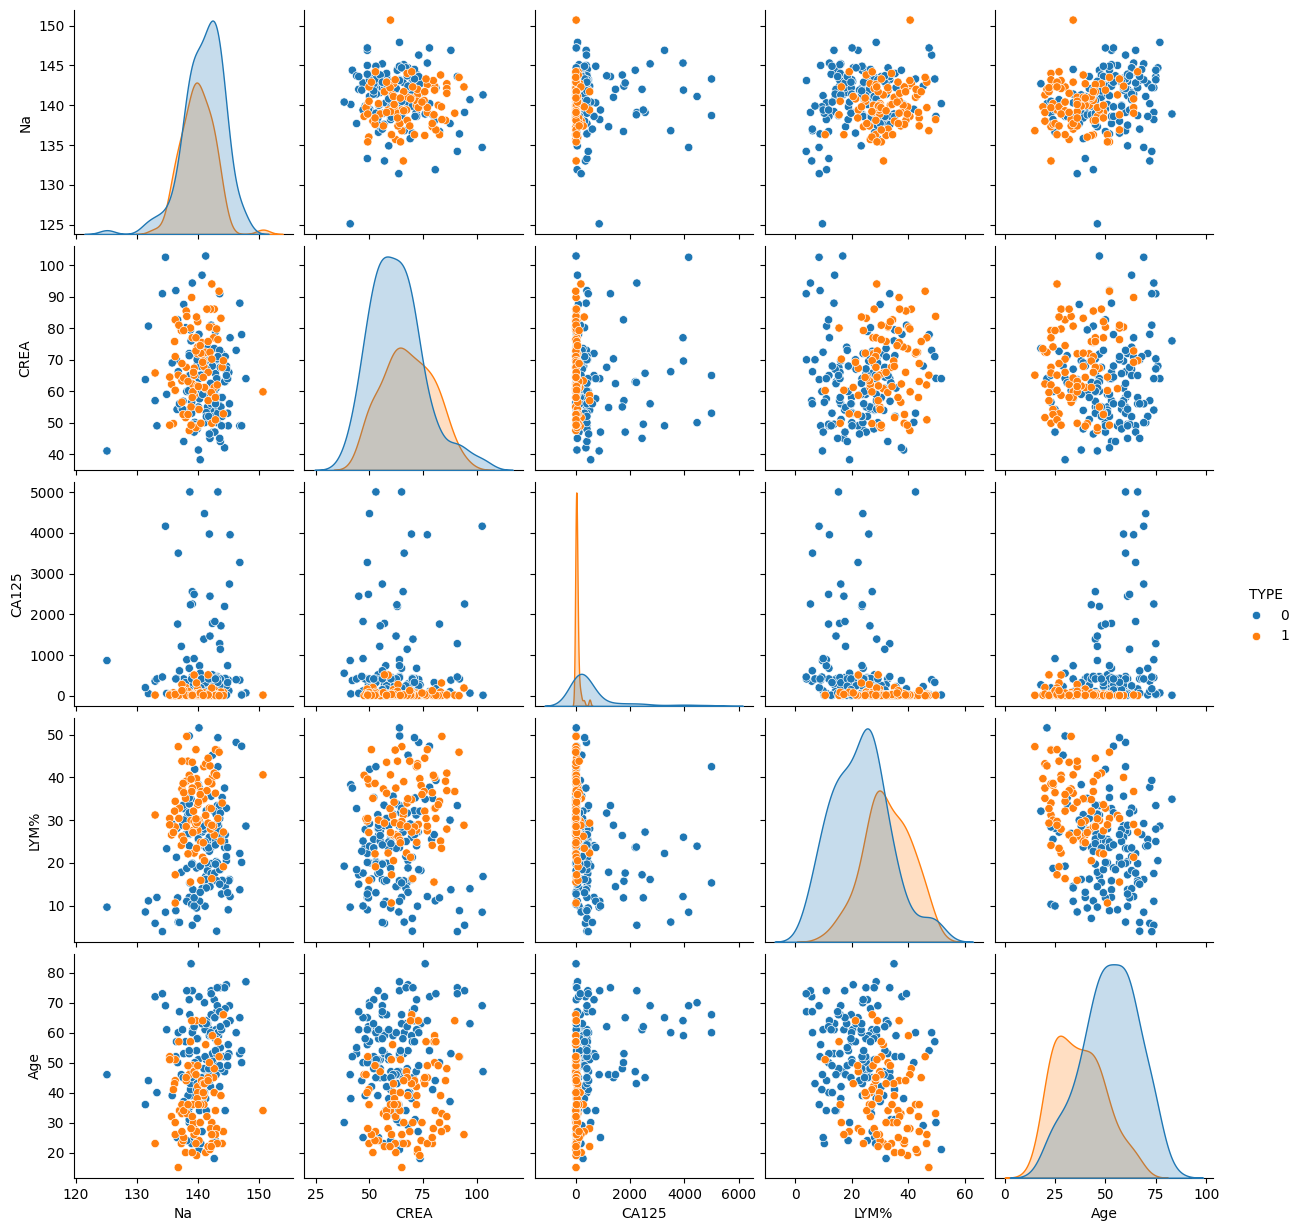

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, cohen_kappa_score, roc_auc_score, classification_report, balanced_accuracy_score
import seaborn as sns

columns = [
    "TYPE",
    "MPV",
    "BASO#",
    "PHOS",
    "GLU.",
    "K",
    "AST",
    "BASO%",
    "Mg",
    "Menopause",
    "CL",
    "CEA",
    "EO#",
    "CA19-9",
    "ALB",
    "IBIL",
    "GGT",
    "MCH",
    "GLO",
    "ALT",
    "DBIL",
    "Age",
    "RDW",
    "PDW",
    "CREA",
    "AFP",
    "HGB",
    "Na",
    "HE4",
    "LYM#",
    "CA125",
    "BUN",
    "LYM%",
    "Ca",
    "AG",
    "MONO#",
    "PLT",
    "NEU",
    "EO%",
    "TP",
    "UA",
    "RBC",
    "PCT",
    "CO2CP",
    "TBIL",
    "HCT",
    "MONO%",
    "MCV",
    "ALP"
]
df = pd.read_csv(r'C:\Users\choua\Desktop\kaggle dataset\ovarien_cancer\Supplementary data 3(Imputed training data without C).csv')

X=df.drop(['TYPE'], axis=1).values
y=df['TYPE'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



sns.pairplot(data = df, vars=['Na', 'CREA', 'CA125', 'LYM%', 'Age'], hue='TYPE', diag_kind='kde')







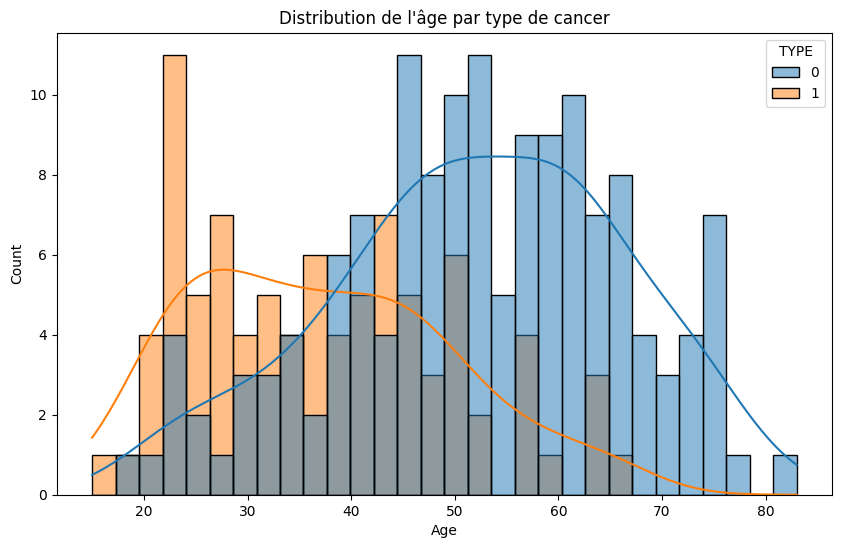

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# Exemple avec la variable "Age"
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x="Age", hue="TYPE", bins=30, kde=True)
plt.title("Distribution de l'âge par type de cancer")
plt.show()

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, train_test_split, cross_val_score
from sklearn.metrics import classification_report



df = pd.read_csv(r'C:\Users\choua\Desktop\kaggle dataset\ovarien_cancer\Supplementary data 3(Imputed training data without C).csv')

X=df.drop(['TYPE'], axis=1)
y=df['TYPE']


numeric_features = X.select_dtypes(include=['int64', 'float64']).columns

preprocessor =Pipeline(steps=[('scaler', StandardScaler())]) 


xgboost_model = Pipeline(steps=[('preprocessor',preprocessor),
                                ('classifier',XGBClassifier())])

rf_model=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('classifier',RandomForestClassifier())
])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# hyperparamater grid 
xgb_params = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 5],
    'classifier__learning_rate':[0.01,0.1]
    
}

rf_params={
    'classifier__n_estimators':[100,200],
    'classifier__max_depth':[3,5],
    'classifier__min_samples_split': [2, 5]
}

xgb_search=GridSearchCV(xgboost_model,xgb_params,cv=5,scoring='accuracy')
xgb_search.fit(X_train,y_train)


rf_search=GridSearchCV(rf_model,rf_params,cv=5,scoring='accuracy')
rf_search.fit(X_train,y_train)

best_xgb = xgb_search.best_estimator_
best_rf = rf_search.best_estimator_




print ("best xgboost accuracy:",best_xgb.score(X_test,y_test))
print("best Random Forest accuracy",best_rf.score(X_test,y_test))


print("\nxgboost classification report:")
print(classification_report(y_test,best_xgb.predict(X_test)))

print("\nrandom forest classification report:")
print(classification_report(y_test,best_rf.predict(X_test)))

#cross validatuin scores 
xgb_cv_scores=cross_val_score(best_xgb,X_train,y_train,cv=5,scoring='f1')
print("\nXGBoost cross_validated f1_score:",xgb_cv_scores)
print("Mean XGBoost F1-Score:", xgb_cv_scores.mean())

rf_cv_scores = cross_val_score(best_rf, X_train, y_train, cv=5, scoring='f1')
print("\nRandom Forest Cross-Validated F1-Score:", rf_cv_scores)
print("Mean Random Forest F1-Score:", rf_cv_scores.mean())

best xgboost accuracy: 0.7872340425531915
best Random Forest accuracy 0.8085106382978723

xgboost classification report:
              precision    recall  f1-score   support

           0       0.79      0.85      0.81        26
           1       0.79      0.71      0.75        21

    accuracy                           0.79        47
   macro avg       0.79      0.78      0.78        47
weighted avg       0.79      0.79      0.79        47


random forest classification report:
              precision    recall  f1-score   support

           0       0.81      0.85      0.83        26
           1       0.80      0.76      0.78        21

    accuracy                           0.81        47
   macro avg       0.81      0.80      0.81        47
weighted avg       0.81      0.81      0.81        47


XGBoost cross_validated f1_score: [0.82758621 1.         0.92857143 0.83870968 0.69565217]
Mean XGBoost F1-Score: 0.8581038973600759

Random Forest Cross-Validated F1-Score: [0.88888889 